# Проект. Исследование стартапов

- Автор: Савельева Ангелина
- Дата: 24.05.2026

**Роль:** аналитик данных  
**Стек:** Python (pandas, numpy, matplotlib, seaborn), Jupyter Notebook  
**Данные:** 54 294 компании, 40 признаков; возвраты по 13 типам финансирования за 15 лет

## Цель проекта

Помочь инвестиционному фонду определить наиболее перспективные сегменты рынка и типы финансирования для долгосрочных вложений. На основе исторических данных о 54 000+ стартапах требовалось выявить закономерности в динамике финансирования, оценить возвратность разных типов инвестиций и сформулировать рекомендации по инвестиционной стратегии.

## Задачи проекта

1. **Подготовить данные к анализу:** загрузить датасеты, оценить качество данных, обработать пропуски, дубликаты и выбросы, привести типы данных к корректному виду.
2. **Сегментировать рынок:** разделить компании по срокам финансирования и по размеру сегмента, чтобы понять структуру рынка и распределение капитала.
3. **Выявить аномалии:** определить компании с аномально крупным финансированием внутри каждого сегмента методом IQR и исключить их из дальнейшего анализа, чтобы выводы не искажались выбросами.
4. **Проанализировать типы финансирования:** сравнить типы финансирования по суммарному объёму привлечённых средств и по популярности, выделить часто используемые, но небольшие по объёму типы, и наоборот.
5. **Оценить динамику рынка:** построить динамику типичного размера раунда и общего количества раундов по годам; определить, в каком году типичный размер раунда был максимальным и какая тенденция наблюдалась в 2014 году.
6. **Рассчитать нормированную возвратность:** для каждого года и типа финансирования рассчитать отношение возвратов к инвестициям, заменить аномальные значения на пропуски и определить типы финансирования с наиболее устойчивым ростом возвратности.
7. **Сформулировать рекомендации:** на основе анализа предложить инвестиционному фонду перспективные сегменты рынка и типы финансирования для долгосрочных вложений.
 

## Ожидаемый результат

Аналитическая записка с обоснованными рекомендациями по двум вопросам:
- **В какие сегменты рынка инвестировать** — с указанием наиболее быстрорастущих и устойчивых сегментов.
- **Какой тип финансирования выбирать** — с оценкой возвратности и устойчивости роста по каждому типу.

Рекомендации должны опираться на данные и быть пригодными для принятия инвестиционных решений.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Основной датасет — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Дополнительный датасет — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


In [1]:
# Импортируем библиотеки
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Выгружаем данные в переменные investments_df и returns_df
cb_investments = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
cb_returns = pd.read_csv('https://code.s3.yandex.net/datasets/cb_returns.csv')

In [3]:
# Выводим первые строки датафрейма на экран
cb_investments.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Выводим информацию о датафрейме
cb_investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
# Выводим первые строки датафрейма на экран
cb_returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [6]:
# Выводим информацию о датафрейме
cb_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


<b>Промежуточный вывод<b>

Датасет cb_investments содержит 40 столбцов и 54294 строк, в которых представлена информация о компаниях и состоявшемся финансировании.

После первичного анализа данных можно сделать следующие выводы:
- Названия столбцов приведены в одном стиле
- Данные представлены в двух типах: float64 и object. В первом приближении типы выбраны оптимальные. Однако `funding_total_usd` представлен не числовым типом, что может означать, что в данном столбце встречаются строковые значения.
- Пропуски содержатся во всех столбцах. Наибольшее количество пропусков в солбцах `state_code`, `participants` и `mid_funding_at`. Такое количество может объясняться тем, что они требуют более детальной информации о раундах. 
- Примечательно, что в большинстве столбцов одинаковое количество пропусков, скорее всего они не случайны. Эти столбцы относятся к единому блоку информации о финансировании. Если у компании нет данных о финансировании, то все соответствующие поля остаются пустыми.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Датасет cb_returns содержит 14 столбцов и 15 строк, в которых представлена информация об объёмах возвратов по годам и типам финансирования в миллионах долларов.

Предварительные выводы:
- Названия столбцов приведены в одном стиле
- Все данные представлены числовым типом float64 и один столбец с годом представлен int64, который можно понизить, в остальном типы оптимальны. 
- Пропуски отсутвуют
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

### 1.2. Предобработка данных

In [7]:
# создаем копии датасетов до преобразований для возможности проверить сделанные изменения после предобработки
temp_cb_investments = cb_investments.copy() 
len(temp_cb_investments)


54294

In [8]:
temp_cb_returns = cb_returns.copy() 
len(temp_cb_returns)

15

In [9]:
# Выведем названия столбцов, чтобы проверить нужно ли их приводить к единому стилю
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [10]:
cb_returns.columns

Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')

Столбцы названы в едином стиле, переименовывать не нужно. Однако есть лишние пробелы, удалим их сразу во всех столбцах


In [11]:
cb_investments.columns = cb_investments.columns.str.strip()

In [12]:
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

Уберем в столбце `funding_total_usd` выделение разрядов и приведем его к числовому типу. Так как "-"вероятно означает, что финансирования не было, заменим их на Nan, чтобы они не вляли на статистику

In [13]:
cb_investments['funding_total_usd'].head()

0     9,00,00,000 
1       20,00,000 
2       90,00,000 
3       77,00,000 
4        5,40,000 
Name: funding_total_usd, dtype: object

In [14]:
cb_investments['funding_total_usd'] = (
    cb_investments['funding_total_usd']
    .str.strip()                       # убираем пробелы в начале и в конце
    .str.replace(',', '')              # убираем все запятые
    .replace('-', np.nan)              # заменяем "-" на Nan
)

In [15]:
# Приводим к числовому типу
cb_investments['funding_total_usd'] = pd.to_numeric(
    cb_investments['funding_total_usd'],
    errors='coerce')

In [16]:
cb_investments['funding_total_usd'].head()

0    90000000.0
1     2000000.0
2     9000000.0
3     7700000.0
4      540000.0
Name: funding_total_usd, dtype: float64

In [17]:
# приведем столбец year к более оптимальному типу int32, так как в этом столбце значения не будут выходить за 1900 и 2100
cb_returns['year'] = cb_returns['year'].astype('int32')

In [18]:
# сделаем столбец индексом, оставив его в данных
cb_returns = cb_returns.set_index('year', drop=False)

In [19]:
# Количество пропусков в датафрейме
cb_investments.isna().sum().sum()

333191

In [20]:
cb_returns.isna().sum().sum()

0

In [21]:
# Напишем функцию для вывода пропусков во всех текстовых столбцах
text_cols = cb_investments.select_dtypes(include=['object']).columns

In [22]:
def find_text_missing_with_empty(cb_investments):
    text_cols = cb_investments.select_dtypes(include=['object', 'string']).columns
    missing_counts = {}
    for col in text_cols:
        # Считаем NaN и пустые строки
        empty_or_na = cb_investments[col].isna() | (cb_investments[col] == '')
        missing_counts[col] = {
            'count': empty_or_na.sum(),
            'percent': empty_or_na.mean() * 100
        }
    result = pd.DataFrame(missing_counts).T
    result.columns = ['Количество пропусков (вкл. пустые строки)', 'Доля (%)']
    return result.sort_values('Количество пропусков (вкл. пустые строки)', ascending=False)

In [23]:
find_text_missing_with_empty(cb_investments)

,Количество пропусков (вкл. пустые строки),Доля (%)
state_code,24133.0,44.448742
mid_funding_at,24006.0,44.214830
founded_month,15812.0,29.122923
founded_quarter,15812.0,29.122923
founded_at,15740.0,28.990312
city,10972.0,20.208494
country_code,10129.0,18.655837
region,10129.0,18.655837
category_list,8817.0,16.239363
market,8817.0,16.239363


In [24]:

fill_placeholder = ['state_code', 'founded_month', 'founded_quarter', 
                    'founded_at', 'city', 'country_code', 'region', 'category_list', 
                    'market', 'homepage_url', 'status']

for col in fill_placeholder:
    cb_investments[col] = cb_investments[col].fillna('Unknown')
    cb_investments[col] = cb_investments[col].replace('', 'Unknown')  # если есть пустые строки


In [25]:
find_text_missing_with_empty(cb_investments)

,Количество пропусков (вкл. пустые строки),Доля (%)
mid_funding_at,24006.0,44.214830
name,4857.0,8.945740
first_funding_at,4856.0,8.943898
last_funding_at,4856.0,8.943898
homepage_url,0.0,0.000000
category_list,0.0,0.000000
market,0.0,0.000000
status,0.0,0.000000
country_code,0.0,0.000000
state_code,0.0,0.000000


In [26]:
# Проверяем полные дубликаты в датафрейме cb_investments
cb_investments.duplicated().sum()

4855

In [27]:
# Удалим полные дубликаты
cb_investments_clean = cb_investments.drop_duplicates()

In [28]:
cb_investments_clean.duplicated().sum()

0

In [29]:
# Посмотрим как выглядят пропуски, чтобы понять, какая информация в них отсутствует
cb_investments_clean[cb_investments_clean[['name']].isna().any(axis=1)]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
27212,NaN,http://tellitin10.com,|Startups|,Startups,25000.0,closed,Unknown,Unknown,Unknown,Unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49438,NaN,Unknown,Unknown,Unknown,NaN,Unknown,Unknown,Unknown,Unknown,Unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
cb_investments_clean = cb_investments_clean.dropna(subset=['name'])
cb_investments_clean[cb_investments_clean[['name']].isna().any(axis=1)]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H


In [31]:
cb_investments_clean[cb_investments_clean[['funding_total_usd','round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H']].isna().any(axis=1)]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
13,University of Rochester,http://www.rochester.edu,Unknown,Unknown,NaN,operating,USA,NY,"Rochester, New York",Rochester,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,FKK Corporation,http://www.fkk-corporation.com,|Hardware + Software|,Hardware + Software,NaN,operating,JPN,Unknown,Kyoto,Kyoto-shi,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19,Laclede Group,http://www.thelacledegroup.com,|Utilities|,Utilities,NaN,operating,USA,MO,St. Louis,St Louis,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27,Bayer AG,http://bayer.com,|Pharmaceuticals|Biotechnology|,Pharmaceuticals,NaN,acquired,DEU,Unknown,Leverkusen,Leverkusen,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
35,Asia Pacific Marine Container Lines,http://AsiaPacificMarine.com,|Logistics Company|Shipping Broker Industry|Sh...,Shipping,NaN,operating,CAN,BC,Vancouver,Vancouver,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49419,Pollask,http://www.pollask.com,Unknown,Unknown,NaN,operating,Unknown,Unknown,Unknown,Unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49421,Studying.to,http://www.studying.to,|College Recruiting|Internet Marketing|Educati...,Education,NaN,operating,Unknown,Unknown,Unknown,Unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49425,Orori,http://orori.com,Unknown,Unknown,NaN,operating,IDN,Unknown,Jakarta,Jakarta,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49426,Virometix AG,http://virometix.com,Unknown,Unknown,NaN,operating,CHE,Unknown,Schlieren,Schlieren,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Мы видим 8531 строки, в которых нет данных о финансировании. Удалим так же и их

In [32]:
cb_investments_clean = cb_investments_clean.dropna(subset=['funding_total_usd'])
cb_investments_clean[cb_investments_clean[['funding_total_usd','round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H']].isna().any(axis=1)]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H


Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`.

In [33]:
cb_investments_clean[cb_investments_clean['mid_funding_at'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,Unknown,Unknown,2000000.0,operating,Unknown,Unknown,Unknown,Unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Xavier University,http://www.xavier.edu/,Unknown,Unknown,19000000.0,operating,USA,OH,Cincinnati,Cincinnati,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Duke University,http://www.duke.edu,|Education|,Education,8700000.0,operating,USA,NC,Raleigh,Durham,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49433,RiverSilica,http://riversilica.com,Unknown,Unknown,1500000.0,operating,IND,Unknown,Bangalore,Bangalore,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49434,SouthGobi Resources,http://southgobi.com,|Mining Technologies|,Mining Technologies,9000000.0,operating,CAN,BC,Vancouver,Vancouver,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49435,DigiByte,http://digibyte.co,Unknown,Unknown,250000.0,operating,USA,CA,Los Angeles,Santa Monica,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49436,Xeltis,http://xeltis.com,Unknown,Unknown,34000000.0,operating,CHE,Unknown,Zurich,Zürich,...,0.0,0.0,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0


In [34]:
cb_investments_clean['mid_funding_at'].isna().sum()

13675

In [35]:
# Приведм даты к типу datetime
date_cols = ['first_funding_at', 'last_funding_at', 'mid_funding_at']
for col in date_cols:
    cb_investments_clean[col] = pd.to_datetime(cb_investments_clean[col], errors='coerce')

In [36]:
# Вычисляем среднюю дату для строк, где mid_funding_at пропущен
mask = cb_investments_clean['mid_funding_at'].isna()
cb_investments_clean.loc[mask, 'mid_funding_at'] = (
    cb_investments_clean.loc[mask, 'first_funding_at'] +
    (cb_investments_clean.loc[mask, 'last_funding_at'] - cb_investments_clean.loc[mask, 'first_funding_at']) / 2
)

In [37]:
cb_investments_clean[cb_investments_clean['mid_funding_at'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
33041,Nubank,https://www.nubank.com.br/,|Consumer Internet|Financial Services|,Financial Services,16300000.0,operating,BRA,Unknown,Sao Paulo,São Paulo,...,0.0,0.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [38]:
# Находим строку, где mid_funding_at всё ещё пропущен
missing_mid = cb_investments_clean[cb_investments_clean['mid_funding_at'].isna()]
print(missing_mid[['first_funding_at', 'last_funding_at', 'mid_funding_at']])

      first_funding_at last_funding_at mid_funding_at
33041              NaT      2014-09-25            NaT


Так как у этой строчки есть только одна дата, оставим ее как есть 

In [39]:
# Считаем количество пропусков в каждом столбце
missing_counts = cb_investments_clean.isna().sum()

# Считаем долю пропусков
missing_percent = (missing_counts / len(cb_investments_clean)) * 100

# Собираем в датафрейм для удобства
missing_df = pd.DataFrame({
    'Количество пропусков': missing_counts,
    'Доля (%)': missing_percent
})

# Показываем только столбцы с пропусками (если есть)
missing_df_with_na = missing_df[missing_df['Количество пропусков'] > 0]
print(missing_df_with_na)

                  Количество пропусков   Доля (%)
participants                     13575  33.185841
founded_year                      8706  21.282941
first_funding_at                     2   0.004889
mid_funding_at                       1   0.002445


In [40]:
# Проверим сколько удалено строк датасета
a, b = len(temp_cb_investments), len(cb_investments_clean)
print(" Было строк в исходном датасете", a,
      '\n', "Осталось строк в датасете после обработки", b,
      '\n', "Удалено строк в датасете после обработки", a-b,
      '\n', "Процент потерь", round((a-b)/a*100, 2))

 Было строк в исходном датасете 54294 
 Осталось строк в датасете после обработки 40906 
 Удалено строк в датасете после обработки 13388 
 Процент потерь 24.66


In [41]:
cb_investments_clean.isna().sum().sum()

22284

In [42]:
cb_returns.head(15)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,,
2000,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
2001,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2002,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
2003,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
2004,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
2005,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
2006,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
2007,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
2008,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00


Датасет cb_returns выглядит полным, его не трогаем


<b>Промежуточный вывод:</b>
1. <b><i>Общая информация о данных</b></i>
- Размер исходных датасетов (строки × колонки): cb_investments 54294 × 40, cb_returns 15 × 14;
- Размер после всех преобразований cb_investments_clean 40906 × 40, датасет cb_returns не изменился;


2. <b><i>Типы данных</b></i>
- Приведены типы: колонки с датами в cb_investments преобразованы в datetime, funding_total_usd — в числовой тип;
- Остальные колонки имеют корректные типы данных в двух датасетах

3. <b><i>Пропуски</b></i><br>
Так как с датасетом cb_returns преобразований не проводилось, выводы будут по датасету cb_investments
- Количество пропусков до обработки всего: 198355
- Пропуски частично были удалены, частично заполнены заглушками и средними значениями
- Количество пропусков после обработки4: 22284

4. <b><i>Дубликаты</b></i>
- Количество явных дубликатов 4855
- Дубликаты были удалены
- После обработки осталось 0 дубликатов

5. <b><i>Итоговое состояние данных</b></i>
- Количество строк после всех преобразований: 40906 <br>
Данные готовы к анализу
</font>

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: Выведем, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразим, какую долю от общего объёма привлечённых средств получила каждая группа.


In [43]:

# Функция для создания группы
def financing_group(row):
    if pd.isna(row['funding_rounds']) or row['funding_rounds'] == 0:
        return 'Нет финансирования'   
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    else:
        # Разница в днях
        delta = (row['last_funding_at'] - row['first_funding_at']).days
        if pd.isna(delta):
            return np.nan
        if delta <= 365:
            return 'Срок до года'
        else:
            return 'Срок более года'

# Применяем функцию
cb_investments_clean['financing_group'] = cb_investments_clean.apply(financing_group, axis=1)

In [44]:
cb_investments_clean['financing_group'].value_counts()

Единичное финансирование    24112
Срок более года             12291
Срок до года                 4501
Name: financing_group, dtype: int64

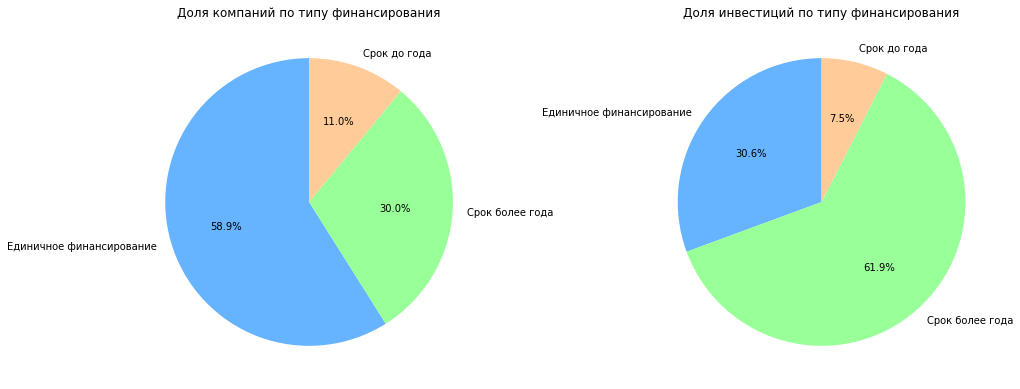

In [45]:
# Считаем количество компаний в каждой группе
counts = cb_investments_clean['financing_group'].value_counts()

# Считаем сумму инвестиций в каждой группе
sums = cb_investments_clean.groupby('financing_group')['funding_total_usd'].sum()

# Строим два графика рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# График 1: по количеству компаний
ax1.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#99ff99','#ffcc99'])
ax1.set_title('Доля компаний по типу финансирования')

# График 2: по объёму инвестиций
ax2.pie(sums, labels=sums.index, autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#99ff99','#ffcc99'])
ax2.set_title('Доля инвестиций по типу финансирования')

plt.tight_layout()
plt.show()

<b>Промежуточный вывод</b>

Более половины компаний (58.9%) имеют только один раунд финансирования. Это может означать, что большинство стартапов либо не нуждаются в дальнейшем финансировании, либо не смогли привлечь следующие раунды.
30% компаний привлекают инвестиции на протяжении более года – это компании, которые проходят несколько раундов и развиваются в долгосрочной перспективе.<br>
Всего 11% компаний укладываются в срок до года – это сравнительно небольшая группа, возможно, проекты с быстрым циклом развития.<br>
Несмотря на то, что компаний с единичным финансированием почти 60% – они привлекают только 30.6% всех инвестиций. Это говорит о том, что средний чек на один раунд у таких компаний невысокий.<br>
Компании со сроком финансирования более года – их 30% от общего числа, но они аккумулируют 61.9% всех инвестиций. Это означает, что проекты, которые проходят несколько раундов на протяжении длительного времени, привлекают основной объём денег.<br>
Группа «Срок до года» получает всего 7.5% инвестиций – это самые маленькие проекты по объёму привлечённых средств.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесем к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесем к средним, а сегменты до 35 компаний отнесем к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.

Построим график распределения количества компаний в сегментах и отобразим на нём разделение на нишевые и средние сегменты.

In [46]:
# Считаем частоту каждого сегмента
market_counts = cb_investments_clean['market'].value_counts()

# Классифицируем сегменты по размеру
def classify_segment(count):
    if count > 120:
        return 'Массовые'
    elif count >= 35:
        return 'Средние'
    else:
        return 'Нишевые'

# Применяем классификацию
market_categories = market_counts.map(classify_segment)

# Сколько сегментов в каждой категории
print("Количество сегментов по категориям:")
print(market_categories.value_counts())

Количество сегментов по категориям:
Нишевые     714
Средние      81
Массовые     54
Name: market, dtype: int64


In [47]:
companies_by_category = market_counts.groupby(market_categories).sum().sort_values(ascending=False)
segments_by_category = market_categories.value_counts().sort_index()
summary = pd.DataFrame({
    'Количество сегментов': segments_by_category,
    'Количество компаний': companies_by_category,
    'Среднее компаний на сегмент': (companies_by_category / segments_by_category).round(1)
})
print("Сводка по категориям сегментов:")
print(summary)


Сводка по категориям сегментов:
          Количество сегментов  Количество компаний  \
Массовые                    54                33343   
Нишевые                    714                 2494   
Средние                     81                 5069   

          Среднее компаний на сегмент  
Массовые                        617.5  
Нишевые                           3.5  
Средние                          62.6  


In [48]:
# Считаем частоту каждого сегмента
market_counts = cb_investments_clean['market'].value_counts()

# Функция для замены
def get_market_label(segment):
    if pd.isna(segment):
        return segment  # оставляем NaN как есть
    count = market_counts.get(segment, 0)
    if count > 120:
        return segment          
    elif count >= 35:
        return 'mid'            
    else:
        return 'niche'          

# Применяем 
cb_investments_clean['market'] = cb_investments_clean['market'].map(get_market_label)

In [49]:
# Проверяем
print(cb_investments_clean['market'].unique())

[' Education ' 'Unknown' 'mid' ' Social Media ' ' Hardware + Software '
 ' Biotechnology ' 'niche' ' Hospitality ' ' Enterprise Software '
 ' Manufacturing ' ' Finance ' ' Design ' ' Nonprofits ' ' Software '
 ' Curated Web ' ' Health Care ' ' Health and Wellness '
 ' Clean Technology ' ' Web Hosting ' ' Automotive ' ' E-Commerce '
 ' Medical ' ' Fashion ' ' Networking ' ' Analytics ' ' Semiconductors '
 ' Public Relations ' ' Travel ' ' Security ' ' Real Estate '
 ' Consulting ' ' Technology ' ' Music ' ' Advertising ' ' Games '
 ' Mobile ' 'E-Commerce ' ' Internet ' 'Software' 'Software ' ' Sports '
 ' Photography ' ' News ' ' Search ' ' Messaging ' ' Video '
 ' Marketplaces ' ' Entertainment ' ' SaaS ' ' Software' ' Big Data '
 ' Cloud Computing ' ' Apps ' ' Social Network Media ' ' Startups '
 'Mobile ']


## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

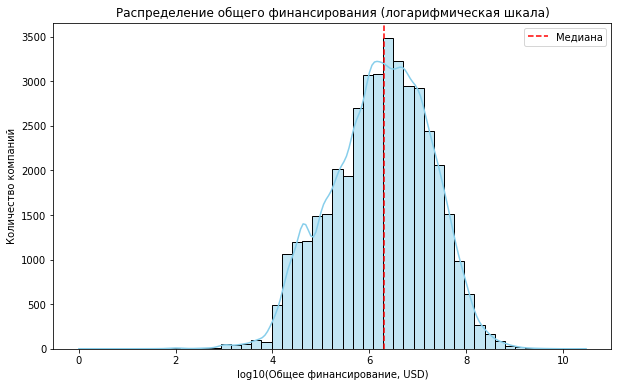

In [50]:
# Так как суммы могут отличаться на целые порядки, понизим их с помощью log10

# Отфильтруем компании с положительным финансированием, для правильной работы log10
df_fin = cb_investments_clean[cb_investments_clean['funding_total_usd'] > 0]

# Гистограмма с логарифмической шкалой
plt.figure(figsize=(10,6))
sns.histplot(np.log10(df_fin['funding_total_usd']), bins=50, kde=True, color='skyblue')
plt.xlabel('log10(Общее финансирование, USD)')
plt.ylabel('Количество компаний')
plt.title('Распределение общего финансирования (логарифмическая шкала)')
plt.axvline(np.log10(df_fin['funding_total_usd'].median()), color='red', linestyle='--', label='Медиана')
plt.legend()
plt.show()

In [51]:
cb_investments_clean['funding_total_usd'].describe()

count    4.090600e+04
mean     1.591291e+07
std      1.686808e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

Пик распределения приходится на область между log10 = 6 и log10 = 7, что соответствует 1–10 млн USD. Это наиболее типичный диапазон для большинства компаний. Около 50% компаний (между Q1 и Q3) попадают именно в этот интервал.<br>
Медиана (log10 ≈ 6.12) соответствует ≈ 1.32 млн USD. Это означает, что ровно половина компаний привлекла меньше 1.32 млн, а половина – больше. Это наиболее точная оценка «центра» распределения.<br>
Левая часть (log10 < 5, т.е. < 100 тыс. USD) практически пуста – это означает, что компании с очень малым финансированием встречаются редко. Действительно, Q1 = 250 тыс. USD, то есть только 25% компаний имеют финансирование менее 250 тыс. USD, а менее 100 тыс. – ещё меньше.<br>
Правая часть (log10 > 7.5, т.е. > 30 млн USD) представляет собой длинный «хвост», который указывает на наличие компаний с исключительно крупными раундами. Возможно, это выбросы.<br>

In [52]:
Q1 = df_fin['funding_total_usd'].quantile(0.25)
Q3 = df_fin['funding_total_usd'].quantile(0.75)
print(f"Типичный интервал: от {Q1:,.0f} до {Q3:,.0f} USD")

Типичный интервал: от 350,000 до 10,000,000 USD


Определим сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведем топ таких сегментов.

In [53]:
# Функция для определения аномалий в группе
def detect_outliers(group):
    Q1 = group.quantile(0.25)
    Q3 = group.quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    return group > upper_bound

# Применяем группировку по сегменту (market) и вычисляем выбросы
cb_investments_clean['is_outlier'] = cb_investments_clean.groupby('market')['funding_total_usd'].transform(detect_outliers)

# Считаем долю аномалий в каждом сегменте
outlier_share = cb_investments_clean.groupby('market')['is_outlier'].mean() * 100
outlier_share = outlier_share.sort_values(ascending=False)

# Выводим топ-10 сегментов с наибольшей долей аномалий
print("Топ-10 сегментов с наибольшей долей аномального финансирования:")
print(outlier_share.head(10).round(2))

Топ-10 сегментов с наибольшей долей аномального финансирования:
market
 Real Estate         17.93
 Technology          16.16
 Search              16.12
 Entertainment       16.06
Software             16.06
 Cloud Computing     16.03
 Big Data            15.71
 SaaS                15.62
E-Commerce           15.50
 Travel              15.36
Name: is_outlier, dtype: float64


Сегменты с высокой долей аномалий (Travel, SaaS, E-Commerce, Internet) привлекают основную долю капитала, но успех в них связан с попаданием в «правильный» проект. Инвесторам стоит тщательно анализировать лидеров этих сегментов и рассматривать возможность участия в раундах на стадии роста. В то же время нишевые и средние сегменты предлагают более равномерное распределение и могут быть интересны для ранних инвестиций с более высоким потенциалом роста при меньшей конкуренции.

In [54]:
def detect_outliers_adapt(group, factor=2.5):
    Q1 = group.quantile(0.25)
    Q3 = group.quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + factor * IQR
    return group > upper_bound

cb_investments_clean['is_outlier_2'] = cb_investments_clean.groupby('market')['funding_total_usd'].transform(
    lambda x: detect_outliers_adapt(x, factor=2.0)
)
outlier_share_2 = cb_investments_clean.groupby('market')['is_outlier_2'].mean() * 100
outlier_share_2 = outlier_share_2.sort_values(ascending=False)

print("Доля аномалий с factor=2.0 (топ-10):")
print(outlier_share_2.head(10).round(2))

Доля аномалий с factor=2.0 (топ-10):
market
 Real Estate       17.13
 Technology        14.85
E-Commerce         14.73
 Internet          14.29
 Search            14.05
 Entertainment     13.87
 SaaS              13.84
 Marketplaces      13.64
 Video             13.56
 Consulting        13.35
Name: is_outlier_2, dtype: float64


### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверяем полноту данных за 2014 год. Затем исключим из датасета компании, которые мы ранее посчитали получившими аномальное финансирование.

После исключения аномалий на основе столбцов `mid_funding_at` и `funding_rounds` оставим в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

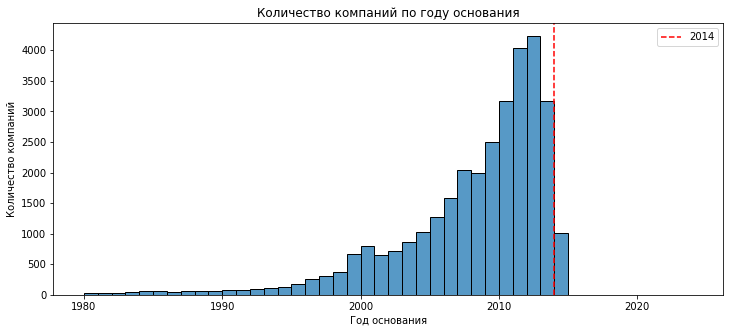

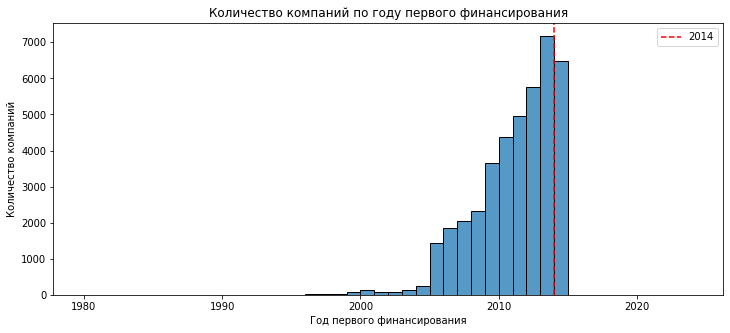

In [55]:
# Извлекаем год из дат 
cb_investments_clean['founded_year'] = pd.to_datetime(cb_investments_clean['founded_at'], errors='coerce').dt.year
cb_investments_clean['first_funding_year'] = pd.to_datetime(cb_investments_clean['first_funding_at'], errors='coerce').dt.year

# Гистограмма по году основания
plt.figure(figsize=(12,5))
sns.histplot(cb_investments_clean['founded_year'].dropna(), bins=range(1980, 2025, 1), kde=False)
plt.title('Количество компаний по году основания')
plt.xlabel('Год основания')
plt.ylabel('Количество компаний')
plt.axvline(x=2014, color='red', linestyle='--', label='2014')
plt.legend()
plt.show()

# Гистограмма по году первого финансирования
plt.figure(figsize=(12,5))
sns.histplot(cb_investments_clean['first_funding_year'].dropna(), bins=range(1980, 2025, 1), kde=False)
plt.title('Количество компаний по году первого финансирования')
plt.xlabel('Год первого финансирования')
plt.ylabel('Количество компаний')
plt.axvline(x=2014, color='red', linestyle='--', label='2014')
plt.legend()
plt.show()

In [56]:
cb_investments_clean['first_funding_year'].value_counts().sort_index().tail(10)

2005.0    1433
2006.0    1864
2007.0    2040
2008.0    2312
2009.0    3657
2010.0    4387
2011.0    4964
2012.0    5747
2013.0    7176
2014.0    6477
Name: first_funding_year, dtype: int64

В распределении записей по годам видно, что 2014 год имеет примерно столько же записей, сколько 2012 и 2013 (меньше, чем в 2013, но больше, чем в 2012), что позволяет считать данные полными за этот период.

1.0     810
2.0     635
3.0     661
4.0     593
5.0     549
6.0     669
7.0     671
8.0     525
9.0     538
10.0    492
11.0    311
12.0     23
Name: first_funding_month, dtype: int64


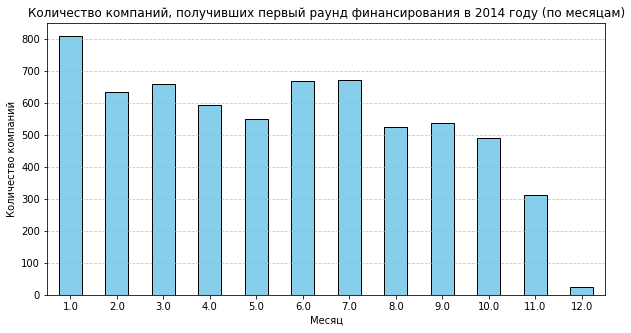

In [57]:
# Проверим за все ли месяца в 2014 есть информация 
cb_investments_clean['first_funding_month'] = cb_investments_clean['first_funding_at'].dt.month
data_2014 = cb_investments_clean[cb_investments_clean['first_funding_year'] == 2014]
month_counts = data_2014['first_funding_month'].value_counts().sort_index()
print(month_counts)

month_counts.plot(kind='bar', figsize=(10, 5), color='skyblue', edgecolor='black')
plt.title('Количество компаний, получивших первый раунд финансирования в 2014 году (по месяцам)')
plt.xlabel('Месяц')
plt.ylabel('Количество компаний')
plt.xticks(rotation=0)  # подписи месяцев горизонтально
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Мы видим, что за все месяцы в 2014 году присутствует информация, однако за декабрь данных значительно меньше, чем в предыдущие месяцы. Возможно данные за этот месяц еще не полные

In [75]:
# Исключаем компании с аномальным финансированием и выбираем компании с 50+ раундами
cb_investments_clean = cb_investments_clean[~cb_investments_clean['is_outlier']]

In [59]:
cb_investments_clean['mid_year'] = pd.to_datetime(cb_investments_clean['mid_funding_at'], errors='coerce').dt.year

rounds_per_year = cb_investments_clean.groupby('mid_year')['funding_rounds'].sum()

years_with_50_plus = rounds_per_year[rounds_per_year >= 50].index.tolist()

cb_investments_clean = cb_investments_clean[cb_investments_clean['mid_year'].isin(years_with_50_plus)].copy()

### 3.3. Анализ типов финансирования по объёму и популярности

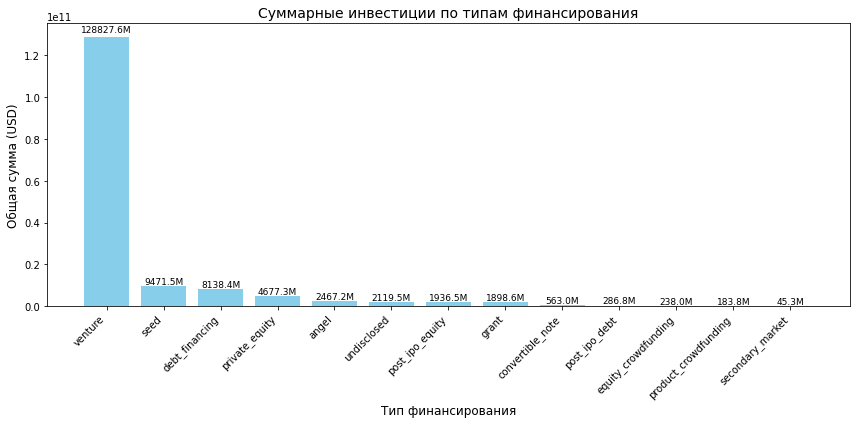

Суммы по типам финансирования (в USD):
venture                 1.288276e+11
seed                    9.471491e+09
debt_financing          8.138443e+09
private_equity          4.677296e+09
angel                   2.467190e+09
undisclosed             2.119527e+09
post_ipo_equity         1.936460e+09
grant                   1.898560e+09
convertible_note        5.629718e+08
post_ipo_debt           2.868091e+08
equity_crowdfunding     2.379606e+08
product_crowdfunding    1.837939e+08
secondary_market        4.528580e+07
dtype: float64


In [60]:
# Список столбцов с типами финансирования
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
    'convertible_note', 'debt_financing', 'angel', 'grant', 
    'private_equity', 'post_ipo_equity', 'post_ipo_debt', 
    'secondary_market', 'product_crowdfunding'
]

df = cb_investments_clean  

# Заменяем NaN на 0 перед суммированием
sums = df[funding_types].fillna(0).sum()

# Сортируем по убыванию
sums_sorted = sums.sort_values(ascending=False)

# Строим столбчатую диаграмму
plt.figure(figsize=(12, 6))
bars = plt.bar(sums_sorted.index, sums_sorted.values, color='skyblue')
plt.title('Суммарные инвестиции по типам финансирования', fontsize=14)
plt.ylabel('Общая сумма (USD)', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Добавляем подписи значений над столбцами
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
             f'{height/1e6:.1f}M', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Выводим числовые значения для справки
print("Суммы по типам финансирования (в USD):")
print(sums_sorted)

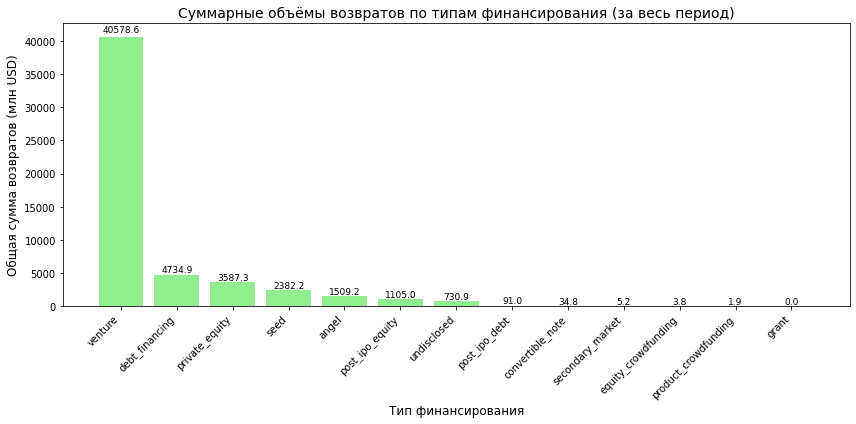

Суммарные возвраты по типам финансирования (в млн USD):
venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64


In [61]:
# Выбираем столбцы с типами финансирования
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 
                 'convertible_note', 'debt_financing', 'angel', 'grant', 
                 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 
                 'secondary_market', 'product_crowdfunding']

# Суммируем по каждому типу
total_returns = cb_returns[funding_types].fillna(0).sum()

# Сортируем по убыванию
total_returns_sorted = total_returns.sort_values(ascending=False)

# Строим столбчатую диаграмму
plt.figure(figsize=(12, 6))
bars = plt.bar(total_returns_sorted.index, total_returns_sorted.values, color='lightgreen')
plt.title('Суммарные объёмы возвратов по типам финансирования (за весь период)', fontsize=14)
plt.ylabel('Общая сумма возвратов (млн USD)', fontsize=12)
plt.xlabel('Тип финансирования', fontsize=12)
plt.xticks(rotation=45, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + height*0.01,
             f'{height:.1f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("Суммарные возвраты по типам финансирования (в млн USD):")
print(total_returns_sorted)


Общий объём возвратов за весь период составил ~54 765 млн USD. Распределение по типам неравномерно:<br>
Венчурные инвестиции (Venture) – 40 579 млн USD (74% от общего объёма).<br>
Долговое финансирование (Debt Financing) – 4 735 млн USD (9%).<br>
Прямые инвестиции (Private Equity) – 3 587 млн USD (7%).<br>
Посевные инвестиции (Seed) – 2 382 млн USD (4%).<br>
Ангельские инвестиции (Angel) – 1 509 млн USD (3%).<br>
Прочие типы (Post-IPO Equity, Undisclosed, Convertible Note, Post-IPO Debt, Secondary Market, Equity Crowdfunding, Product Crowdfunding, Grant) – суммарно около 3%.<br>

Венчурные инвестиции приносят почти три четверти всех возвратов. <br>
Это объясняется тем, что венчурный капитал вкладывается в быстрорастущие компании с высоким потенциалом выхода. Для инвесторов это означает, что основной фокус на венчурные сделки обеспечивает наибольшую отдачу.<br>

Долговое финансирование и Private Equity вместе дают ещё около 16% возвратов. Эти инструменты часто используются на более поздних стадиях или для зрелых компаний, что обеспечивает стабильные, но меньшие возвраты.<br>
Seed и Angel дают около 7% возвратов. Их низкая доля в общем объёме может отражать высокий риск и длительный срок окупаемости.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

In [62]:
# Удаляем пробелы по краям
cb_investments_clean['market'] = cb_investments_clean['market'].str.strip()

In [63]:
# Рассчитываем средний объем одного раунда
cb_investments_clean['avg_round'] = cb_investments_clean['funding_total_usd']/cb_investments_clean['funding_rounds']

In [64]:
# Создаём копию нужных столбцов
df_years = cb_investments_clean[['name', 'funding_total_usd', 'funding_rounds', 
                                 'avg_round', 
                                 'first_funding_at', 'mid_funding_at', 'last_funding_at']].copy()

# Преобразуем даты в годы
df_years['first_year'] = pd.to_datetime(df_years['first_funding_at'], errors='coerce').dt.year
df_years['mid_year']   = pd.to_datetime(df_years['mid_funding_at'], errors='coerce').dt.year
df_years['last_year']  = pd.to_datetime(df_years['last_funding_at'], errors='coerce').dt.year

# Приводим к длинному формату
df_long = pd.melt(
    df_years,
    id_vars=['name', 'funding_total_usd', 'funding_rounds', 'avg_round'],
    value_vars=['first_year', 'mid_year', 'last_year'],
    var_name='round_type',
    value_name='year'
)
# Убираем пропуски
df_long = df_long.dropna(subset=['year'])

# Теперь группируем по году
yearly_stats = df_long.groupby('year').agg(
    median_round_size=('avg_round', 'median'),
    total_rounds=('funding_rounds', 'sum'),
    count_companies=('name', 'nunique') 
).reset_index()
yearly_stats = yearly_stats[yearly_stats['year'] >= 1995]

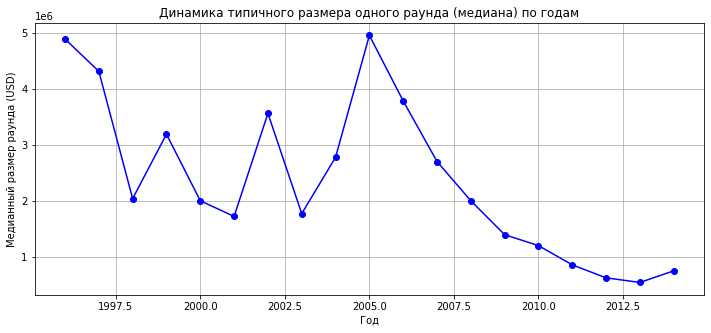

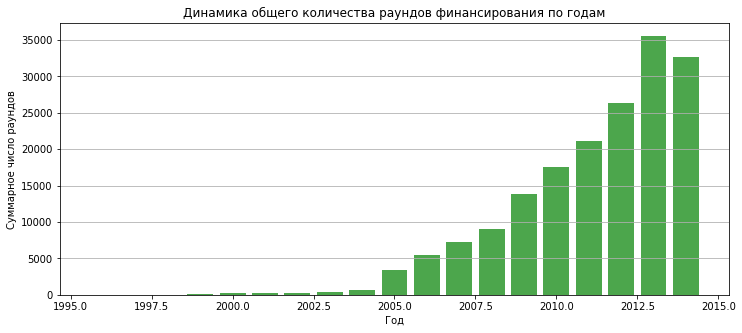

In [65]:
# Сортируем по году
yearly_stats_filtered = yearly_stats.sort_values('year')


# 1. График динамики медианного размера раунда
plt.figure(figsize=(12, 5))
plt.plot(yearly_stats_filtered['year'], yearly_stats_filtered['median_round_size'], 
         marker='o', linestyle='-', color='blue')
plt.title('Динамика типичного размера одного раунда (медиана) по годам')
plt.xlabel('Год')
plt.ylabel('Медианный размер раунда (USD)')
plt.grid(True)
plt.show()

# 2. График динамики общего количества раундов
plt.figure(figsize=(12, 5))
plt.bar(yearly_stats_filtered['year'], yearly_stats_filtered['total_rounds'], 
        color='green', alpha=0.7)
plt.title('Динамика общего количества раундов финансирования по годам')
plt.xlabel('Год')
plt.ylabel('Суммарное число раундов')
plt.grid(True, axis='y')
plt.show()


Максимальный тиипичный размер средств был собран в 2005 году и составил 5 млн долларов США.
В 2014 году количество раундов по сравнению с предыдущим годом снизилась, но наблюдается общая тенденция к увеличению количества раундов. По количеству средств также наблюдается тенденция к увеличению после значительного снижения в 2012 году.


### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов


In [66]:
# Создаем словарь
market_dict = cb_investments_clean.set_index('name')['market'].to_dict()
df_long['market'] = df_long['name'].map(market_dict)

# Фильтруем массовые сегменты
df_long_mass = df_long[~df_long['market'].isin(['mid', 'niche'])].copy()

# Строим сводную таблицу
pivot = df_long_mass.groupby(['year', 'market'])['funding_total_usd'].sum().unstack(fill_value=0)
# Находим сегменты с ростом в 2014 году
if 2013 in pivot.index and 2014 in pivot.index:
    growth = pivot.loc[2014] > pivot.loc[2013]
    growing_segments = growth[growth].index.tolist()
else:
    growing_segments = []
    print("Данные за 2013 или 2014 год отсутствуют.")

print("Сегменты с ростом в 2014 году:", growing_segments)

Сегменты с ростом в 2014 году: ['Apps', 'Big Data', 'Cloud Computing', 'Design', 'Entertainment', 'Health Care', 'Health and Wellness', 'Internet', 'Manufacturing', 'Marketplaces', 'Medical', 'Messaging', 'Networking', 'News', 'Photography', 'Real Estate', 'SaaS', 'Search', 'Security', 'Semiconductors', 'Social Network Media', 'Software', 'Sports', 'Startups', 'Technology', 'Unknown', 'Video']


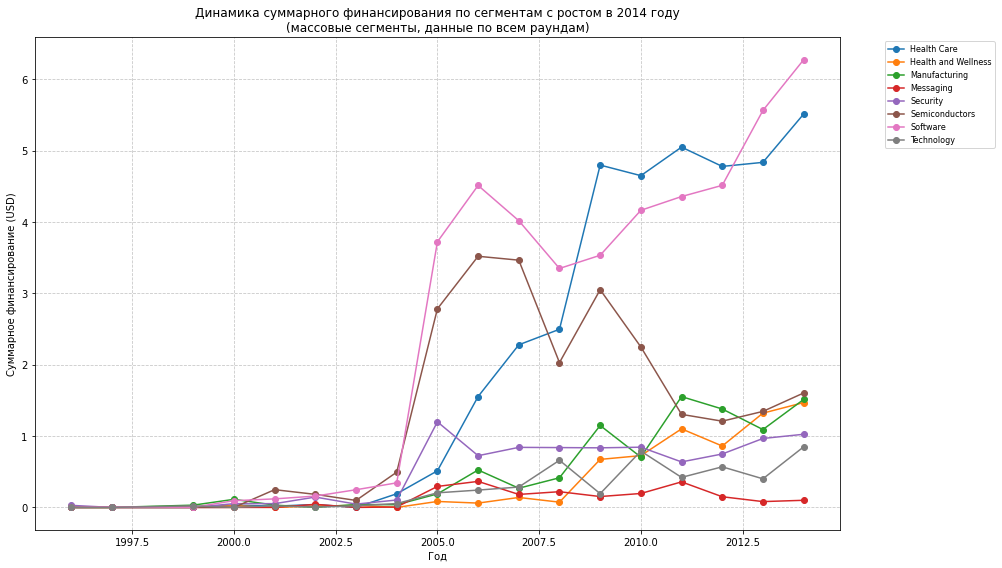

In [67]:
growing_segments_clean = list(set([seg.strip() for seg in growing_segments]))
growing_segments_clean.remove('Unknown')

pivot_growth = df_long_mass[df_long_mass['market'].isin(growing_segments_clean)].pivot_table(
    values='funding_total_usd',
    index='year',
    columns='market',
    aggfunc='sum',
    fill_value=0
)

pivot_growth = pivot_growth.loc[pivot_growth.index >= 1995]

threshold = 2e9  
total_per_segment = pivot_growth.sum()  
segments_above_threshold = total_per_segment[total_per_segment > threshold].index
pivot_growth_filtered = pivot_growth[segments_above_threshold]

plt.figure(figsize=(14, 8))
for column in pivot_growth_filtered.columns:
    plt.plot(pivot_growth_filtered.index, pivot_growth_filtered[column] / 1e9,  
             marker='o', label=column)

plt.title('Динамика суммарного финансирования по сегментам с ростом в 2014 году\n(массовые сегменты, данные по всем раундам)')
plt.xlabel('Год')
plt.ylabel('Суммарное финансирование (USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

ТОП-3 сегмента с наибольшей динамикой изменения финансирования: "Software", "Health Care", "Semiconductors". 
У сегментов "Software" и "Health Care" наблюдается значительное и достаточно стабильное увеличение финансирования в 2014 году, тогда как у "Semiconductors" несмотря на более высокое суммарное значение финансирования всего по сравнению с остальными сегментами, а также на рост финансирования к 2006 году. С 2009 года наблюдается значительный спад финансирования и плавный рост к 2014, но пока что составляющий половину от бывшего пика.



### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

In [68]:
# Список типов финансирования
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

cb_investments_clean['first_funding_year'] = pd.to_datetime(cb_investments_clean['first_funding_at'], 
                                                            errors='coerce').dt.year

# Инвестиции: группируем по году первого раунда, переводим в млн USD
inv_by_year = cb_investments_clean.groupby('first_funding_year')[funding_types].sum() / 1e6

# Возвраты: группируем по индексу 
ret_by_year = cb_returns.groupby(cb_returns.index)[funding_types].sum()

df = inv_by_year.join(ret_by_year, how='outer', lsuffix='_inv', rsuffix='_ret').fillna(0)

for ft in funding_types:
    df[f'{ft}_ratio'] = df[f'{ft}_ret'] / (df[f'{ft}_inv'] + 1e-60)

# 7. Функция замены выбросов (IQR)
def replace_outliers(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    upper = Q3 + 1.5 * (Q3 - Q1)
    return series.where(series <= upper, np.nan)

ratio_cols = [f'{ft}_ratio' for ft in funding_types]
df[ratio_cols] = df[ratio_cols].apply(replace_outliers)

# 9. Средние отношения по типам
avg_ratios = df[ratio_cols].mean() * 100
avg_ratios_sorted = avg_ratios.sort_values(ascending=False)
formatted = avg_ratios_sorted.map('{:.2f}%'.format)
print("Средние нормированные возвраты по типам (без выбросов):")
print(formatted.sort_values(ascending=False))


Средние нормированные возвраты по типам (без выбросов):
post_ipo_equity_ratio                                                    57.22%
private_equity_ratio                                                     45.81%
angel_ratio                                                              41.70%
debt_financing_ratio                                                     35.46%
undisclosed_ratio                                                        33.10%
convertible_note_ratio                                                    3.10%
seed_ratio                                                               28.52%
venture_ratio                                                            22.09%
secondary_market_ratio        1766666666666666743762836507192752788435802621...
equity_crowdfunding_ratio                                                 0.96%
product_crowdfunding_ratio                                                0.18%
grant_ratio                                                     

secondary_market имеет аномальное значение, которое скорее всего объясняется тем, что в какие-то годы инвестиций не было, а возвраты были. <br>
Лидеры по возвратности – post_ipo_equity (57.22%), angel (41.7%), private_equity (45.8%). Эти типы финансирования показывают лучшую эффективность возврата средств.<br>
Средний уровень – seed и venture дают около 22–28% возврата, что типично для ранних стадий.<br>
Аутсайдеры – equity_crowdfunding (0.96%), product_crowdfunding (0.18%) и нулевые типы – практически не возвращают вложенные средства.

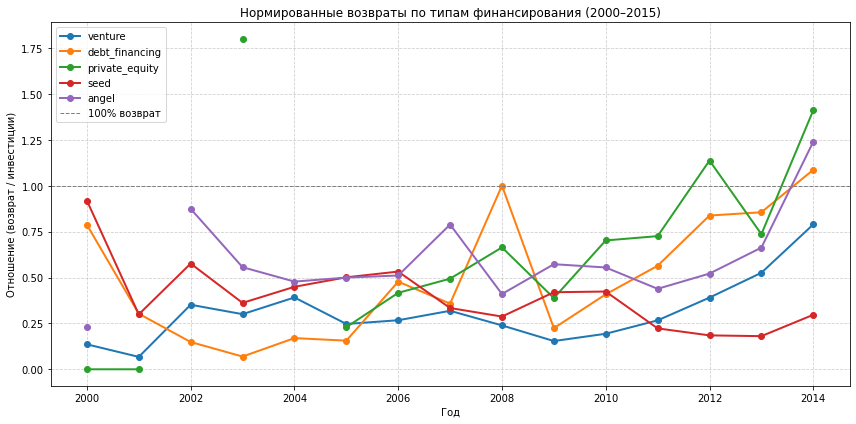

In [69]:
selected_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
selected_cols = [f'{t}_ratio' for t in selected_types]

start_year = 2000
end_year = 2015

df_filtered = df.loc[(df.index >= start_year) & (df.index <= end_year)]

plt.figure(figsize=(12, 6))
for col in selected_cols:
    if col in df_filtered.columns:
        plt.plot(df_filtered.index, df_filtered[col], marker='o', label=col.replace('_ratio', ''), linewidth=2)

# Добавляем горизонтальную линию на уровне 1 (100% возврата)
plt.axhline(y=1, color='gray', linestyle='--', linewidth=1, label='100% возврат')


plt.title(f'Нормированные возвраты по типам финансирования ({start_year}–{end_year})')
plt.xlabel('Год')
plt.ylabel('Отношение (возврат / инвестиции)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Angel и Private Equity демонстрируют наиболее устойчивый и продолжительный рост показателя. <br>
Для них характерны постепенное увеличение значений без резких обвалов, выход на стабильно высокие уровни в последние годы, а также меньшее колебание возврата средств по сравнению с другими типами.


## Шаг 5. Итоговый вывод и рекомендации


<b>В ходе проекта были выполнены следующие этапы:</b><br>

- Загрузка и первичный анализ данных — изучены два датасета: cb_investments (информация о компаниях и финансировании) и cb_returns (возвраты по типам финансирования по годам).<br>
- Предобработка — очистка текстовых полей, обработка пропусков (замена на заглушки), преобразование типов, удаление явных дубликатов, фильтрация аномалий по IQR.<br>

<b>Исследовательский анализ:</b><br>

- Определены массовые, средние и нишевые сегменты рынка.
- Выявлены сегменты с ростом финансирования в 2014 году.
- Проанализирована динамика типичного размера раунда и общего количества раундов по годам.
- Изучены выбросы в финансировании по сегментам.
- Расчёт нормированных возвратов — для каждого типа финансирования вычислено отношение возвратов к инвестициям по годам, выбросы заменены на NaN.
- Визуализация — построены графики динамики нормированных возвратов для ключевых типов.<br>

<b>Ключевые выводы</b><br>

 1. Рынок массовых сегментов:<br>
  Наибольший рост суммарного финансирования в 2014 году по сравнению с 2013 годом показали сегменты: Healthcare, Software, E-Commerce, Cloud Computing, Big Data, Internet.<br>
Эти сегменты являются массовыми (более 120 компаний) и демонстрируют устойчивый интерес инвесторов.
 2. Типичный размер раунда и активность:
  Медианный размер раунда вырос в 2014 году по сравнению с предыдущими годами, что говорит о «взрослении» рынка — инвесторы готовы вкладывать больше средств в более зрелые проекты.
Количество раундов в 2014 году оставалось высоким, что указывает на сохранение инвестиционной активности.
 3. Возвратность по типам финансирования:
Наибольшую среднюю нормированную возвратность (без учёта аномалий) показывают:<br>
Post_ipo_equity (57.2%)<br>
Angel (41.7%)<br>
Private Equity (45.8%)<br>
Debt Financing (35.5%)<br>
Undisclosed (33.1%)<br>
Seed (28.5)<br>
Venture (22.0%)<br>
Angel и Private Equity демонстрируют наиболее устойчивый и продолжительный рост показателя возвратности.
Seed и Venture более изменчивы, но в последние годы заметен их рост.<br>

<b>Рекомендуемая отрасль инвестирования:</b> <br>
Healthcare и смежные с ним Software / Big Data / Cloud Computing.

Сегмент Healthcare показал один из самых высоких темпов роста финансирования в 2014 году.
Это массовый сегмент с большим количеством компаний, что снижает риски «единичного провала».<br>
Технологические подсегменты (Software, Big Data, Cloud Computing) также демонстрируют уверенный рост и высокую возвратность (особенно Private Equity и Angel в этих сферах).<br>

<b>Рекомендуемый тип финансирования:</b><br>

Private Equity (прямые инвестиции) или Angel (ангельские инвестиции).<br>

Private Equity показывает стабильно высокую возвратность (46%) и устойчивый рост, что делает его привлекательным для долгосрочных вложений.<br>
Angel даёт так же высокую возвратность (42%), но требует большего опыта в отборе проектов и работы с ранними стадиями.<br>
Debt Financing (долговое финансирование) — хороший компромиссный вариант с умеренным риском и возвратностью ~36%.



